# ARTI 502 | CIFAR-10 CNN with MaxPooling
The validation-selected model was EfficientNetV2-L pretrained on ImageNet-21k and subsequently fine-tuned on ImageNet-1k, then trained here on CIFAR-10 with an explicit MaxPool2d. Epoch 8 achieved 99.24% validation accuracy and 98.97% official test accuracy (9,897 of 10,000 images).

The saved outputs document the original Colab runs. To read the results, open the notebook without rerunning. To replay all experiments, Task 2 needs the original ImageNet-1k run's CIFAR checkpoint named `model.pt`. The final checkpoint, `best_epoch_8.pt`, is a separate file. The final summary cell can also run on its own using the saved `winner.json`.

## Task 1 – Getting the CIFAR dataset
Download and verify the data. Training/validation indices reproduce the original run.

In [ ]:
import gc, json, math, os, random, sys, subprocess, importlib.util
from pathlib import Path
if importlib.util.find_spec("timm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm==1.0.22"])
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import matplotlib.pyplot as plt
from torchvision import transforms as T
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader, Subset, TensorDataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("Choose the connected L4 or A100 GPU runtime.")
AMP = torch.cuda.is_bf16_supported()
torch.backends.cudnn.benchmark = True
SEED = 502
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
CFG = dict(tag="tf_efficientnetv2_l.in1k", size=384, batch=8)
OUT = Path("./outputs/arti502_completed")
OUT.mkdir(parents=True, exist_ok=True)
DATA_PATH = "./data"
train_data = CIFAR10(DATA_PATH, train=True, download=True)
classes = train_data.classes
rng = np.random.default_rng(SEED)
train_ids, val_ids = [], []
for label in range(10):
    ids = rng.permutation(np.flatnonzero(np.asarray(train_data.targets) == label))
    val_ids.extend(ids[:250].tolist())
    train_ids.extend(ids[250:].tolist())
train_ids, val_ids = sorted(train_ids), sorted(val_ids)
assert not set(train_ids).intersection(val_ids)
assert len(train_ids) == 47500 and len(val_ids) == 2500
print("GPU:", torch.cuda.get_device_name())
print("CIFAR-10:", train_data.data.shape)
print("Training:", len(train_ids), "| Validation:", len(val_ids))
print("Training class counts:", np.bincount(np.array(train_data.targets)[train_ids]))


GPU: NVIDIA L4
CIFAR-10: (50000, 32, 32, 3)
Training: 47500 | Validation: 2500
Training class counts: [4750 4750 4750 4750 4750 4750 4750 4750 4750 4750]


## Task 2 – Defining the network
Define the convolutional backbone, explicit MaxPool2d and ten-class classifier. Load your saved model.pt. The uploaded run fine-tuned the entire backbone before this MaxPooling comparison.

In [ ]:
class CIFARMaxPoolCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(CFG["tag"], pretrained=False, num_classes=10)
        self.max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)

    def features(self, x, use_maxpool=True):
        x = self.backbone.forward_features(x)
        if use_maxpool:
            x = self.max_pool(x)
        return self.avg_pool(x).flatten(1)

    def forward(self, x):
        return self.backbone.classifier(self.features(x))

    def load_original_weights(self, path):
        # model.pt was saved before the parameter-free MaxPool2d was added.
        self.backbone.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))

def accuracy(logits, labels):
    return 100.0 * (logits.argmax(1) == labels).sum().item() / len(labels)

def train_head_one_epoch(head, loader, optimizer):
    head.train()
    for features, labels in loader:
        features, labels = features.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(head(features), labels)
        loss.backward()
        optimizer.step()

@torch.no_grad()
def test_head(head, features, labels, flip_features=None):
    head.eval()
    total_loss, correct = 0.0, 0
    for start in range(0, len(labels), 512):
        stop = start + 512
        target = labels[start:stop].to(DEVICE)
        logits = head(features[start:stop].to(DEVICE)).float()
        if flip_features is None:
            total_loss += F.cross_entropy(logits, target, reduction="sum").item()
            predicted = logits.argmax(1)
        else:
            flip_logits = head(flip_features[start:stop].to(DEVICE)).float()
            probs = (logits.softmax(1) + flip_logits.softmax(1)) / 2
            total_loss += F.nll_loss(probs.clamp_min(1e-30).log(), target, reduction="sum").item()
            predicted = probs.argmax(1)
        correct += (predicted == target).sum().item()
    return dict(loss=total_loss / len(labels), accuracy=100 * correct / len(labels))

def atomic_save(value, path):
    temporary = path.with_suffix(".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)

# Reuse your local checkpoint in the same Colab session.
checkpoint_candidates = sorted(
    Path("./outputs/arti502_transfer").glob("large_1k_validation_*/model.pt"),
    key=lambda p: p.stat().st_mtime,
    reverse=True,
)
WEIGHTS_PATH = checkpoint_candidates[0] if checkpoint_candidates else Path("/content/model.pt")
if not WEIGHTS_PATH.exists():
    from google.colab import files
    uploaded = files.upload()  # Select the model.pt you already downloaded.
    if "model.pt" not in uploaded:
        raise FileNotFoundError("Upload the original file named model.pt.")
    WEIGHTS_PATH = Path("model.pt")
model = CIFARMaxPoolCNN()
model.load_original_weights(WEIGHTS_PATH)
model = model.to(device=DEVICE, memory_format=torch.channels_last)
model.eval()
first_conv = next(layer for layer in model.modules() if isinstance(layer, nn.Conv2d))
print("First convolution:", first_conv)
print("Max pooling:", model.max_pool)
print("Final classifier:", model.backbone.classifier)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


First convolution: Conv2dSame(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
Max pooling: MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
Final classifier: Linear(in_features=1280, out_features=10, bias=True)
Parameters: 117,247,082


## Task 3 – Loading data
Inspect tensor sizes and original images. Evaluation uses resize, ToTensor and Normalize.

Original tensor [N,C,H,W]: (8, 3, 32, 32)


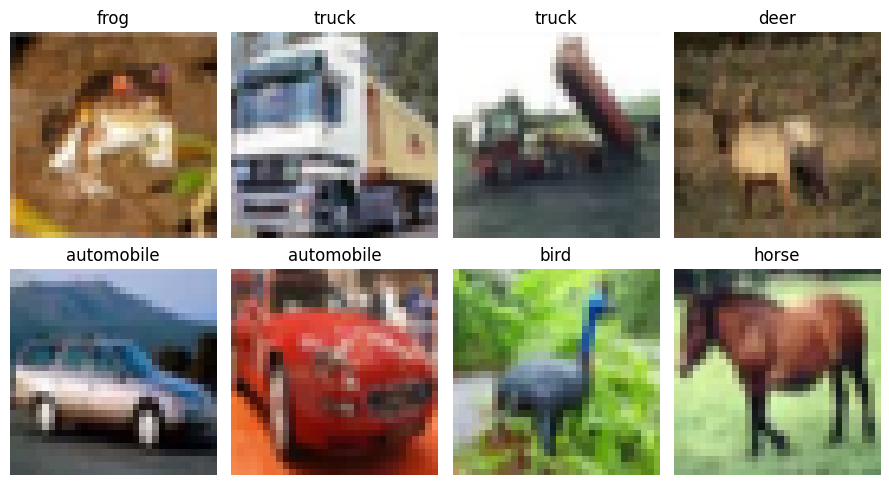

Network input: (8, 3, 384, 384)


In [ ]:
info = timm.get_pretrained_cfg(CFG["tag"])
evaluation_transform = T.Compose([
    T.Resize((CFG["size"], CFG["size"]), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(info.mean, info.std),
])
training_transform = T.Compose([
    T.RandomCrop(32, padding=3, padding_mode="reflect"),
    T.RandomHorizontalFlip(),
    *evaluation_transform.transforms,
])
def make_loader(ids=None, train=True, augmented=False):
    ds = CIFAR10(DATA_PATH, train=train, download=True,
                 transform=training_transform if augmented else evaluation_transform)
    if ids is not None:
        ds = Subset(ds, ids)
    return DataLoader(ds, batch_size=CFG["batch"], shuffle=False,
                      num_workers=min(4, os.cpu_count() or 1), pin_memory=True)

preview_data = CIFAR10(DATA_PATH, train=True, transform=T.ToTensor())
images, labels = next(iter(DataLoader(preview_data, batch_size=8)))
print("Original tensor [N,C,H,W]:", tuple(images.shape))
fig, axes = plt.subplots(2, 4, figsize=(9, 5))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[int(label)])
    ax.axis("off")
fig.tight_layout()
plt.show()
print("Network input:", tuple(next(iter(make_loader(val_ids)))[0].shape))


## Task 4 – Dataset augmentation
Apply and display each suggested augmentation. Original backbone training used crop and horizontal flip. The added color, rotation and noise examples demonstrate the operators on training images.

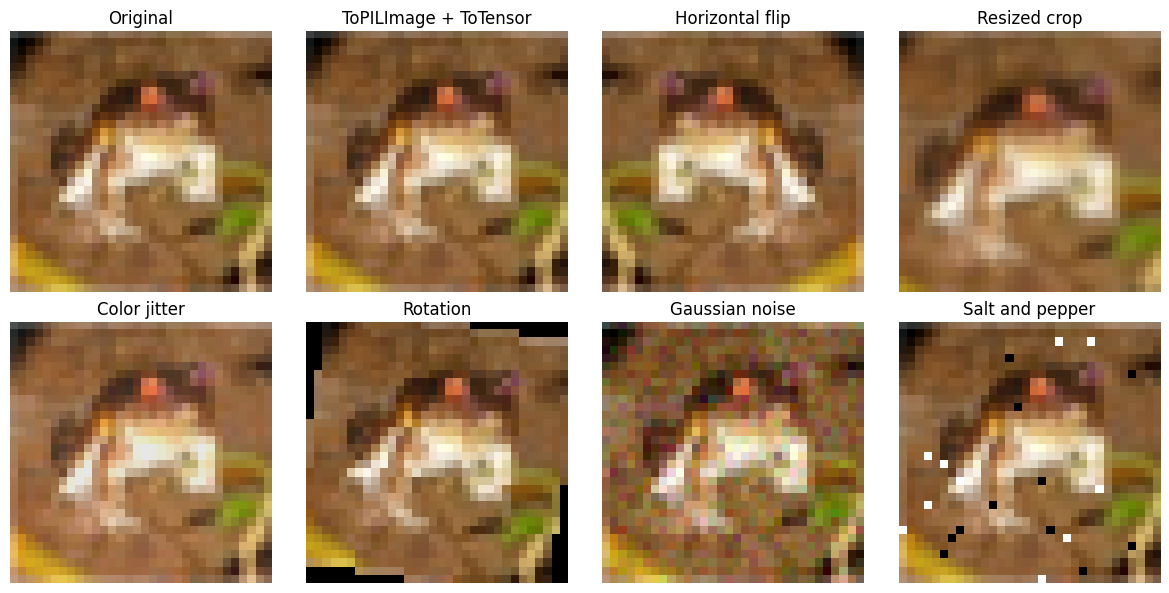

ToTensor range: 0.0 1.0
After Normalize: -1.0 1.0
Original backbone training used crop, flip, resize, ToTensor and Normalize.
The other transformations above are applied demonstrations on training images.


In [ ]:
class AddGaussianNoise:
    def __call__(self, tensor):
        return (tensor + 0.04 * torch.randn_like(tensor)).clamp(0, 1)

class AddSaltPepperNoise:
    def __call__(self, tensor):
        result = tensor.clone()
        mask = torch.rand(tensor.shape[-2:])
        result[:, mask < 0.01] = 0
        result[:, mask > 0.99] = 1
        return result

# Demonstrations apply to training images. The evaluation pipeline stays deterministic.
augmentation_examples = {
    "ToPILImage + ToTensor": T.Compose([T.ToPILImage(), T.ToTensor()]),
    "Horizontal flip": T.Compose([T.ToPILImage(), T.RandomHorizontalFlip(p=1), T.ToTensor()]),
    "Resized crop": T.Compose([T.ToPILImage(), T.RandomResizedCrop(32, scale=(0.7, 1.0)), T.ToTensor()]),
    "Color jitter": T.Compose([T.ToPILImage(), T.ColorJitter(0.2, 0.2, 0.2, 0.05), T.ToTensor()]),
    "Rotation": T.Compose([T.ToPILImage(), T.RandomRotation(15), T.ToTensor()]),
    "Gaussian noise": AddGaussianNoise(),
    "Salt and pepper": AddSaltPepperNoise(),
}
raw = T.ToTensor()(train_data[train_ids[0]][0])
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes.flat[0].imshow(raw.permute(1, 2, 0))
axes.flat[0].set_title("Original")
for ax, (name, transform) in zip(list(axes.flat)[1:], augmentation_examples.items()):
    ax.imshow(transform(raw).permute(1, 2, 0).clamp(0, 1))
    ax.set_title(name)
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "task4_augmentations.png", dpi=150)
plt.show()
normalized = T.Normalize(info.mean, info.std)(raw)
print("ToTensor range:", float(raw.min()), float(raw.max()))
print("After Normalize:", float(normalized.min()), float(normalized.max()))
print("Original backbone training used crop, flip, resize, ToTensor and Normalize.")
print("The other transformations above are applied demonstrations on training images.")


## Task 5 – Training and tuning hyperparameters
Plot the original 10-epoch records. Extract features once with the frozen backbone, then compare two learning rates over two classifier epochs each. Select using validation, evaluate the test split and generate all three requested curves.

### Recorded original backbone run

| Epoch | Training loss (smoothed CE) | Validation accuracy |
|---|---|---|
| 1 | 0.694297 | 97.56% |
| 2 | 0.394341 | 97.88% |
| 3 | 0.348030 | 98.52% |
| 4 | 0.321000 | 98.24% |
| 5 | 0.308037 | 98.84% |
| 6 | 0.301031 | 98.56% |
| 7 | 0.298016 | 98.68% |
| 8 | 0.295769 | 98.48% |
| 9 | 0.292715 | 99.04% |
| 10 | 0.289839 | 98.76% |


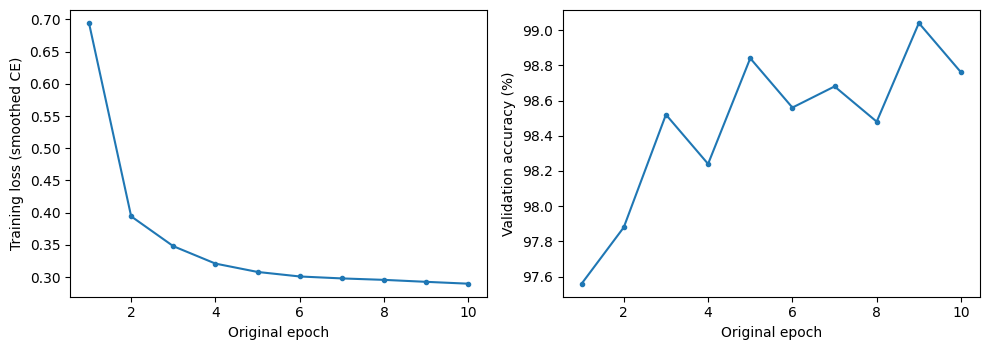

Encoding the 47,500 augmented training images once.
Feature batches 1/5938
Feature batches 500/5938
Feature batches 1000/5938
Feature batches 1500/5938
Feature batches 2000/5938
Feature batches 2500/5938
Feature batches 3000/5938
Feature batches 3500/5938
Feature batches 4000/5938
Feature batches 4500/5938
Feature batches 5000/5938
Feature batches 5500/5938
Encoding validation images.
Feature batches 1/313
Original architecture validation: {'loss': 0.0892228256225586, 'accuracy': 99.0}
With MaxPooling validation: {'loss': 0.05210567398071289, 'accuracy': 99.0}
{'name': 'MaxPool before head tuning', 'lr': 0.0, 'epoch': 0, 'train_loss': 0.0038699184405176263, 'val_loss': 0.05210567398071289, 'val_acc': 99.0}
{'name': 'Head lr=0.0005, epoch=1', 'lr': 0.0005, 'epoch': 1, 'train_loss': 0.0038588078549033717, 'val_loss': 0.05211105155944824, 'val_acc': 99.0}
{'name': 'Head lr=0.0005, epoch=2', 'lr': 0.0005, 'epoch': 2, 'train_loss': 0.0038472878255342183, 'val_loss': 0.05211658782958985, 'va

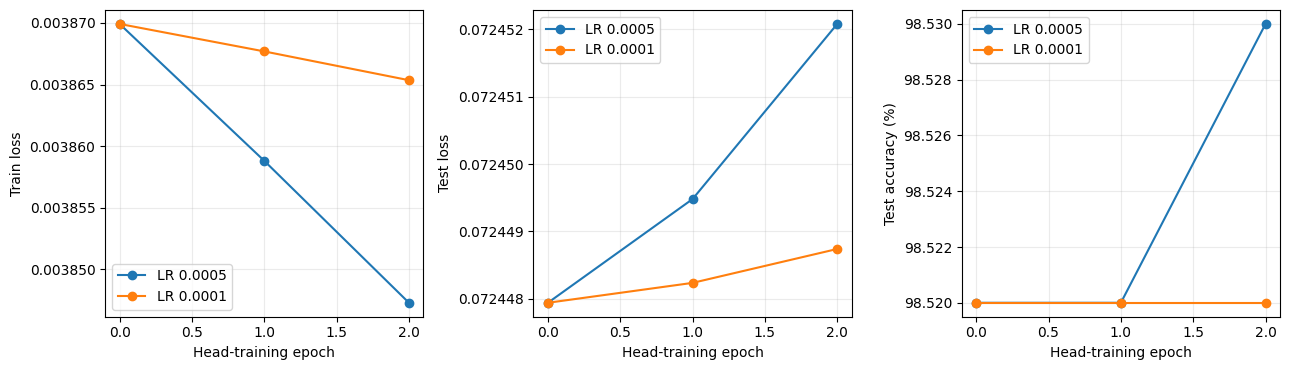

In [ ]:
# The following original training records are copied from your uploaded notebook.
ORIGINAL_HISTORY = [{'epoch': 1, 'train_loss': 0.6942967105263158, 'val_acc': 97.56}, {'epoch': 2, 'train_loss': 0.3943409539473684, 'val_acc': 97.88}, {'epoch': 3, 'train_loss': 0.34802976973684213, 'val_acc': 98.52}, {'epoch': 4, 'train_loss': 0.3209998972039474, 'val_acc': 98.24}, {'epoch': 5, 'train_loss': 0.3080374177631579, 'val_acc': 98.84}, {'epoch': 6, 'train_loss': 0.30103094161184213, 'val_acc': 98.56}, {'epoch': 7, 'train_loss': 0.2980158511513158, 'val_acc': 98.68}, {'epoch': 8, 'train_loss': 0.29576893503289475, 'val_acc': 98.48}, {'epoch': 9, 'train_loss': 0.29271482319078945, 'val_acc': 99.04}, {'epoch': 10, 'train_loss': 0.28983949424342104, 'val_acc': 98.76}]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot([r["epoch"] for r in ORIGINAL_HISTORY], [r["train_loss"] for r in ORIGINAL_HISTORY], marker=".")
axes[1].plot([r["epoch"] for r in ORIGINAL_HISTORY], [r["val_acc"] for r in ORIGINAL_HISTORY], marker=".")
axes[0].set(xlabel="Original epoch", ylabel="Training loss (smoothed CE)")
axes[1].set(xlabel="Original epoch", ylabel="Validation accuracy (%)")
fig.tight_layout()
plt.show()

@torch.no_grad()
def cache_features(loader, include_plain=False, include_flip=False):
    model.eval()
    values, plain_values, flipped_values, targets = [], [], [], []
    for i, (images, labels) in enumerate(loader):
        images = images.to(device=DEVICE, memory_format=torch.channels_last, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP):
            maps = model.backbone.forward_features(images)
            values.append(model.avg_pool(model.max_pool(maps)).flatten(1).float().cpu())
            if include_plain:
                plain_values.append(model.avg_pool(maps).flatten(1).float().cpu())
            if include_flip:
                flipped = model.features(images.flip(-1))
                flipped_values.append(flipped.float().cpu())
        targets.append(labels)
        if i == 0 or (i + 1) % 500 == 0:
            print(f"Feature batches {i+1}/{len(loader)}", flush=True)
    return dict(x=torch.cat(values), y=torch.cat(targets),
                plain=torch.cat(plain_values) if include_plain else None,
                flip=torch.cat(flipped_values) if include_flip else None)

# The backbone stays fixed. Each augmented training image is encoded once.
for parameter in model.backbone.parameters():
    parameter.requires_grad_(False)
for parameter in model.backbone.classifier.parameters():
    parameter.requires_grad_(True)
torch.manual_seed(SEED)
print("Encoding the 47,500 augmented training images once.")
train_cache = cache_features(make_loader(train_ids, augmented=True))
print("Encoding validation images.")
val_cache = cache_features(make_loader(val_ids), include_plain=True)
head = model.backbone.classifier
original_head = {k: v.detach().cpu().clone() for k, v in head.state_dict().items()}
def head_copy():
    return {k: v.detach().cpu().clone() for k, v in head.state_dict().items()}

plain_val = test_head(head, val_cache["plain"], val_cache["y"])
maxpool_val = test_head(head, val_cache["x"], val_cache["y"])
print("Original architecture validation:", plain_val)
print("With MaxPooling validation:", maxpool_val)

records = []
heads = []
def record_head(name, lr, epoch):
    train_score = test_head(head, train_cache["x"], train_cache["y"])
    val_score = test_head(head, val_cache["x"], val_cache["y"])
    records.append(dict(name=name, lr=lr, epoch=epoch, train_loss=train_score["loss"],
                        val_loss=val_score["loss"], val_acc=val_score["accuracy"]))
    heads.append(head_copy())
    print(records[-1], flush=True)

record_head("MaxPool before head tuning", 0.0, 0)
# Each LR experiment starts from your original checkpoint head.
# The fixed feature vectors include one sampled crop/flip per training image.
for lr in (5e-4, 1e-4):
    head.load_state_dict(original_head)
    optimizer = torch.optim.SGD(head.parameters(), lr=lr, momentum=0.9)
    generator = torch.Generator().manual_seed(SEED)
    feature_loader = DataLoader(TensorDataset(train_cache["x"], train_cache["y"]),
                                batch_size=256, shuffle=True, generator=generator)
    for epoch in range(1, 3):
        train_head_one_epoch(head, feature_loader, optimizer)
        record_head(f"Head lr={lr}, epoch={epoch}", lr, epoch)
best_index = max(range(len(records)), key=lambda i: records[i]["val_acc"])
head.load_state_dict(heads[best_index])
chosen = records[best_index]
print("Selected using validation accuracy:", chosen)
atomic_save(dict(model_state=model.state_dict(), model_tag=CFG["tag"], image_size=CFG["size"],
                 architecture="CIFARMaxPoolCNN", max_pool=dict(kernel_size=2, stride=2),
                 selected=chosen, pretraining="ImageNet-1k",
                 backbone_weights_source=str(WEIGHTS_PATH)), OUT / "maxpool_final.pt")

# Selection is complete. Test scores below are used to report the experiment curves.
print("Encoding the official 10,000 test images once.")
test_cache = cache_features(make_loader(train=False), include_flip=True)
assert len(test_cache["y"]) == 10000
for index, row in enumerate(records):
    head.load_state_dict(heads[index])
    metric = test_head(head, test_cache["x"], test_cache["y"])
    row.update(test_loss=metric["loss"], test_acc=metric["accuracy"])
head.load_state_dict(heads[best_index])
final_flip = test_head(head, test_cache["x"], test_cache["y"], test_cache["flip"])
final_report = dict(
    selected_model="EfficientNetV2-L with MaxPool2d",
    selection_metric="validation accuracy", selected=records[best_index],
    single_view_test_accuracy=records[best_index]["test_acc"],
    single_view_test_loss=records[best_index]["test_loss"],
    flip_test_accuracy=final_flip["accuracy"],
    train_loss_definition="Unsmoothed CE on fixed augmented training features at selected head weights",
    validation_size=2500, train_size=47500, test_size=10000,
    original_architecture_val=plain_val, maxpool_before_tuning_val=maxpool_val,
    experiments=records, original_history=ORIGINAL_HISTORY,
)
print("\nFINAL MODEL")
print("Selected:", chosen["name"])
print(f"Final train loss: {chosen['train_loss']:.4f}")
print(f"Final test loss: {chosen['test_loss']:.4f}")
print(f"Final test accuracy: {chosen['test_acc']:.2f}%")
print(f"Flip-averaged test accuracy: {final_flip['accuracy']:.2f}%")
print("\nExperiment | lr | head epoch | train loss | val accuracy | test loss | test accuracy")
for r in records:
    print(f"{r['name']} | {r['lr']} | {r['epoch']} | {r['train_loss']:.4f} | "
          f"{r['val_acc']:.2f}% | {r['test_loss']:.4f} | {r['test_acc']:.2f}%")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, key, title in zip(axes, ["train_loss", "test_loss", "test_acc"],
                           ["Train loss", "Test loss", "Test accuracy (%)"]):
    for lr in (5e-4, 1e-4):
        curve = [records[0]] + [r for r in records[1:] if r["lr"] == lr]
        ax.plot([r["epoch"] for r in curve], [r[key] for r in curve], marker="o", label=f"LR {lr}")
    ax.set(xlabel="Head-training epoch", ylabel=title)
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "task5_train_test_curves.png", dpi=160)
plt.show()


### Selecting test-time views on validation data

In [ ]:
# Run after Tasks 1–5 in the SAME Colab session.
from pathlib import Path
from torchvision.transforms import functional as TF
from PIL import Image
import json
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Load the model selected on validation before evaluating extra views.
saved = torch.load(OUT / "maxpool_final.pt", map_location="cpu", weights_only=True)
model.load_state_dict(saved["model_state"])
model.eval()
del saved

class CIFARViews(Dataset):
    def __init__(self, train):
        self.dataset = CIFAR10(DATA_PATH, train=train, download=False)
        self.ids = val_ids if train else list(range(len(self.dataset)))

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        image, label = self.dataset[self.ids[index]]
        padded = TF.pad(image, 2, padding_mode="reflect")
        originals = [image] + [TF.crop(padded, y, x, 32, 32)
                               for y, x in [(0, 0), (0, 4), (4, 0), (4, 4)]]
        views = []
        for picture in originals:
            views.extend([evaluation_transform(picture),
                          evaluation_transform(TF.hflip(picture))])
        return torch.stack(views), label

@torch.no_grad()
def predict_views(train):
    loader = DataLoader(CIFARViews(train), batch_size=2, shuffle=False,
                        num_workers=2, pin_memory=True)
    outputs, targets = [], []
    for step, (views, labels) in enumerate(loader):
        count, view_count, channels, height, width = views.shape
        flat = views.reshape(-1, channels, height, width)
        batches = []
        for images in flat.split(CFG["batch"]):
            images = images.to(device=DEVICE, memory_format=torch.channels_last,
                               non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP):
                logits = model(images)
            batches.append(logits.float().softmax(1).cpu())
        outputs.append(torch.cat(batches).reshape(count, view_count, 10))
        targets.append(labels)
        if step == 0 or (step + 1) % 500 == 0:
            print(f"{'Validation' if train else 'Test'} batches {step+1}/{len(loader)}",
                  flush=True)
    return torch.cat(outputs), torch.cat(targets)

def combined_probabilities(views, setting):
    if setting == "single":
        return views[:, 0]
    centered = views[:, :2].mean(1)
    shifted = views[:, 2:].mean(1)
    return (1 - setting) * centered + setting * shifted

print("Selecting the view-averaging method on validation images.")
validation_views, validation_labels = predict_views(True)
settings = ["single", 0.0, 0.25, 0.5, 0.75, 1.0]
validation_scores = []
for setting in settings:
    probabilities = combined_probabilities(validation_views, setting)
    score = 100 * (probabilities.argmax(1) == validation_labels).float().mean().item()
    validation_scores.append(score)
    print(f"Setting {setting}: validation accuracy {score:.2f}%")
# Fixed order favors single-view predictions on a validation tie.
best = max(range(len(settings)), key=validation_scores.__getitem__)
chosen_view_setting = settings[best]
decision = dict(setting=chosen_view_setting,
                validation_accuracy=validation_scores[best],
                candidates=dict(zip(map(str, settings), validation_scores)))
(OUT / "tta_validation_choice.json").write_text(json.dumps(decision, indent=2))
print("Selected on validation:", decision)

test_views, test_labels = predict_views(False)
probabilities = combined_probabilities(test_views, chosen_view_setting)
correct = int((probabilities.argmax(1) == test_labels).sum())
result = dict(decision=decision, correct=correct, total=len(test_labels),
              test_accuracy=100 * correct / len(test_labels),
              test_loss=F.nll_loss(probabilities.clamp_min(1e-30).log(), test_labels).item())
(OUT / "tta_final_test.json").write_text(json.dumps(result, indent=2))
print(f"Validation-selected method: {chosen_view_setting}")
print(f"Final test accuracy: {result['test_accuracy']:.2f}% ({correct}/{len(test_labels)})")
print(f"Final test loss: {result['test_loss']:.4f}")
print("Report saved:", OUT / "tta_final_test.json")

Selecting the view-averaging method on validation images.
Validation batches 1/1250
Validation batches 500/1250
Validation batches 1000/1250
Setting single: validation accuracy 99.00%
Setting 0.0: validation accuracy 99.04%
Setting 0.25: validation accuracy 99.04%
Setting 0.5: validation accuracy 99.08%
Setting 0.75: validation accuracy 98.96%
Setting 1.0: validation accuracy 98.92%
Selected on validation: {'setting': 0.5, 'validation_accuracy': 99.08000230789185, 'candidates': {'single': 99.00000095367432, '0.0': 99.04000163078308, '0.25': 99.04000163078308, '0.5': 99.08000230789185, '0.75': 98.96000027656555, '1.0': 98.91999959945679}}
Test batches 1/5000
Test batches 500/5000
Test batches 1000/5000
Test batches 1500/5000
Test batches 2000/5000
Test batches 2500/5000
Test batches 3000/5000
Test batches 3500/5000
Test batches 4000/5000
Test batches 4500/5000
Test batches 5000/5000
Validation-selected method: 0.5
Final test accuracy: 98.56% (9856/10000)
Final test loss: 0.0553
Report s

### Fine-tuning the final stages of the ImageNet-1k model

In [ ]:
# Run in the SAME Colab session after the completed improve_tta.py cell.
# Starts from your saved MaxPooling CNN and fine-tunes its final convolutional stages.
import gc, json, math, random, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR10

required = ["model", "CFG", "OUT", "train_ids", "training_transform",
            "predict_views", "combined_probabilities", "DEVICE", "AMP"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run this in the existing notebook after TTA. Missing: " + ", ".join(missing))
EXTRA_EPOCHS = 3
MAX_LR = 0.001
EFFECTIVE_BATCH = 64
TAIL_DIR = OUT / "tail_finetuning_v1"
TAIL_DIR.mkdir(exist_ok=True)
BEST_PATH = TAIL_DIR / "best_maxpool.pt"
RESUME_PATH = TAIL_DIR / "resume.pt"
SOURCE_PATH = OUT / "maxpool_final.pt"

def save_atomic(value, path):
    temp = path.with_suffix(".tmp")
    torch.save(value, temp)
    temp.replace(path)

def choose_validation_views(views, labels):
    choices = ["single", 0.0, 0.25, 0.5, 0.75, 1.0]
    candidates = []
    for setting in choices:
        probabilities = combined_probabilities(views, setting)
        correct = int((probabilities.argmax(1) == labels).sum())
        loss = F.nll_loss(probabilities.clamp_min(1e-30).log(), labels).item()
        candidates.append(dict(setting=setting, correct=correct,
                               val_accuracy=100 * correct / len(labels), val_loss=loss))
    # Validation accuracy first, validation loss to break ties.
    return max(candidates, key=lambda r: (r["correct"], -r["val_loss"]))

resume = torch.load(RESUME_PATH, map_location="cpu", weights_only=True) if RESUME_PATH.exists() else None
saved = resume if resume is not None else torch.load(SOURCE_PATH, map_location="cpu", weights_only=True)
model.load_state_dict(saved["model_state"])
del saved

# Fine-tune the final TWO convolutional stages, the final convolution and classifier.
for parameter in model.parameters():
    parameter.requires_grad_(False)
for module in (model.backbone.blocks[-2:], model.backbone.conv_head,
               model.backbone.bn2, model.backbone.classifier):
    for parameter in module.parameters():
        parameter.requires_grad_(True)
trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.SGD(trainable, lr=MAX_LR, momentum=0.9,
                            nesterov=True, weight_decay=1e-5)
start_epoch = 0
history = []
if resume is not None:
    optimizer.load_state_dict(resume["optimizer"])
    start_epoch, history = resume["epoch"], resume["history"]
    best_choice = resume["best_choice"]
    best_epoch = resume["best_epoch"]
    del resume
else:
    print("Measuring the starting model on validation views.", flush=True)
    views, labels = predict_views(True)
    best_choice = choose_validation_views(views, labels)
    best_epoch = 0
    save_atomic(dict(model_state=model.state_dict(), choice=best_choice, epoch=0),
                BEST_PATH)
    del views, labels
print("Starting best validation result:", best_choice, flush=True)
print("Trainable parameters:", sum(p.numel() for p in trainable), flush=True)
assert EFFECTIVE_BATCH % CFG["batch"] == 0
accumulation = EFFECTIVE_BATCH // CFG["batch"]
dataset = Subset(CIFAR10(DATA_PATH, train=True, download=False,
                        transform=training_transform), train_ids)

try:
    for epoch in range(start_epoch, EXTRA_EPOCHS):
        seed = 1502 + epoch
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        loader = DataLoader(dataset, batch_size=CFG["batch"], shuffle=True,
                            num_workers=2, pin_memory=True)
        # Eval mode keeps BatchNorm statistics stable with microbatches of eight.
        # Gradients remain enabled for the selected trainable layers.
        model.eval()
        optimizer.zero_grad(set_to_none=True)
        loss_total = torch.zeros((), device=DEVICE)
        tic = time.perf_counter()
        for step, (images, labels) in enumerate(loader):
            progress = (epoch + step / len(loader)) / EXTRA_EPOCHS
            lr = MAX_LR * (0.05 + 0.95 * (1 + math.cos(math.pi * progress)) / 2)
            for group in optimizer.param_groups:
                group["lr"] = lr
            images = images.to(device=DEVICE, memory_format=torch.channels_last,
                               non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP):
                logits = model(images)
                loss = F.cross_entropy(logits.float(), labels,
                                       label_smoothing=0.05, reduction="sum")
            group_start = (step // accumulation) * EFFECTIVE_BATCH
            count = min(EFFECTIVE_BATCH, len(dataset) - group_start)
            (loss / count).backward()
            if (step + 1) % accumulation == 0 or step + 1 == len(loader):
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)
            loss_total += loss.detach()
            if step == 0 or (step + 1) % 500 == 0:
                elapsed = (time.perf_counter() - tic) / 60
                estimated = elapsed * len(loader) / (step + 1)
                print(f"Extra epoch {epoch+1}/{EXTRA_EPOCHS}, batch {step+1}/{len(loader)}"
                      f" | elapsed {elapsed:.1f} min | estimated epoch {estimated:.1f} min",
                      flush=True)
        views, labels = predict_views(True)
        choice = choose_validation_views(views, labels)
        row = dict(epoch=epoch+1, train_loss=loss_total.item()/len(dataset), **choice)
        history.append(row)
        if (choice["correct"], -choice["val_loss"]) > (best_choice["correct"], -best_choice["val_loss"]):
            best_choice, best_epoch = choice, epoch+1
            save_atomic(dict(model_state=model.state_dict(), choice=best_choice,
                             epoch=best_epoch), BEST_PATH)
        save_atomic(dict(model_state=model.state_dict(), optimizer=optimizer.state_dict(),
                         epoch=epoch+1, history=history, best_choice=best_choice,
                         best_epoch=best_epoch), RESUME_PATH)
        (TAIL_DIR / "history.json").write_text(json.dumps(history, indent=2))
        print("Completed:", row, "| best epoch:", best_epoch, flush=True)
        del views, labels
except KeyboardInterrupt:
    print("Stopped. Best model and completed-epoch resume files are in", TAIL_DIR)
    raise

best = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
model.load_state_dict(best["model_state"])
del best
optimizer.zero_grad(set_to_none=True)
del optimizer, trainable
gc.collect()
torch.cuda.empty_cache()

print("Validation selection complete. Measuring the selected model on the official test.", flush=True)
views, labels = predict_views(False)
probabilities = combined_probabilities(views, best_choice["setting"])
correct = int((probabilities.argmax(1) == labels).sum())
tail_report = dict(
    best_extra_epoch=best_epoch, chosen_on_validation=best_choice,
    correct=correct, total=len(labels), test_accuracy=100 * correct / len(labels),
    test_loss=F.nll_loss(probabilities.clamp_min(1e-30).log(), labels).item(),
    history=history, model_path=str(BEST_PATH),
)
(TAIL_DIR / "final_test.json").write_text(json.dumps(tail_report, indent=2))
print(f"Best extra epoch: {best_epoch}")
print(f"Validation accuracy: {best_choice['val_accuracy']:.2f}%")
print(f"View setting: {best_choice['setting']}")
print(f"Final test accuracy: {tail_report['test_accuracy']:.2f}% ({correct}/{len(labels)})")
print(f"Final test loss: {tail_report['test_loss']:.4f}")
print("Best weights:", BEST_PATH)
print("Final report:", TAIL_DIR / "final_test.json")


Measuring the starting model on validation views.
Validation batches 1/1250
Validation batches 500/1250
Validation batches 1000/1250
Starting best validation result: {'setting': 0.5, 'correct': 2477, 'val_accuracy': 99.08, 'val_loss': 0.0398341566324234}
Trainable parameters: 95731426
Extra epoch 1/3, batch 1/5938 | elapsed 0.3 min | estimated epoch 1556.6 min
Extra epoch 1/3, batch 500/5938 | elapsed 1.2 min | estimated epoch 14.3 min
Extra epoch 1/3, batch 1000/5938 | elapsed 2.1 min | estimated epoch 12.7 min
Extra epoch 1/3, batch 1500/5938 | elapsed 3.1 min | estimated epoch 12.1 min
Extra epoch 1/3, batch 2000/5938 | elapsed 4.0 min | estimated epoch 11.9 min
Extra epoch 1/3, batch 2500/5938 | elapsed 4.9 min | estimated epoch 11.7 min
Extra epoch 1/3, batch 3000/5938 | elapsed 5.9 min | estimated epoch 11.6 min
Extra epoch 1/3, batch 3500/5938 | elapsed 6.8 min | estimated epoch 11.5 min
Extra epoch 1/3, batch 4000/5938 | elapsed 7.7 min | estimated epoch 11.5 min
Extra epoch 1/

### ImageNet-21k experiment and final selection
Both pretrained variants used the same 47,500 training images and 2,500 validation images. The ImageNet-21k run trained all layers with MaxPooling, using SGD with Nesterov momentum (0.9), weight decay 0.00001, a peak backbone learning rate of 0.005 and classifier rate of 0.025, and batches of 8 accumulated to 64. Training used random crop and horizontal flip. The model and view averaging were selected on validation accuracy, with validation loss breaking ties.

The recorded validation results were 99.08% for the ImageNet-1k model and 99.24% for the ImageNet-21k model. Official test accuracy was 98.56% and 98.97%, respectively. The cell below contains the script previously run via Colab's upload prompt. Its output is the original run transcript.

In [ ]:
# Extra Task 5 experiment. Run in the same L4/A100 session after the tail run.
# Uses the notebook's CIFAR split, transforms, ten views and validation decision rule.
import gc
import hashlib
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR10


class ChallengeCNN(CIFARMaxPoolCNN):
    """Keep Task 2's exact forward method, starting from different backbone weights."""
    def __init__(self, tag, pretrained):
        nn.Module.__init__(self)
        self.backbone = timm.create_model(tag, pretrained=pretrained, num_classes=10)
        self.max_pool = nn.MaxPool2d(2, 2)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)


def challenge_rank(choice):
    return choice["correct"], -choice["val_loss"]


@torch.inference_mode()
def challenge_views(network, train):
    network.eval()
    loader = DataLoader(CIFARViews(train), batch_size=2, shuffle=False,
                        num_workers=2, prefetch_factor=1, pin_memory=True)
    outputs, targets = [], []
    for step, (pictures, labels) in enumerate(loader, 1):
        n, v, channels, h, w = pictures.shape
        parts = []
        for batch in pictures.reshape(-1, channels, h, w).split(CFG["batch"]):
            batch = batch.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP):
                logits = network(batch)
            parts.append(logits.float().softmax(1).cpu())
        outputs.append(torch.cat(parts).reshape(n, v, -1))
        targets.append(labels)
        if step % 500 == 0:
            print(f"  Evaluation batches {step}/{len(loader)}", flush=True)
    return torch.cat(outputs), torch.cat(targets)


def challenge_train_epoch(network, dataset, optimizer, epoch, config):
    seed = config["seed"] + epoch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    loader = DataLoader(dataset, batch_size=config["batch"], shuffle=True,
                        num_workers=2, pin_memory=True)
    # Small GPU batches: keep pretrained batch-normalization statistics fixed.
    network.train()
    for layer in network.modules():
        if isinstance(layer, nn.modules.batchnorm._BatchNorm):
            layer.eval()
    optimizer.zero_grad(set_to_none=True)
    effective = config["effective_batch"]
    accumulate = effective // config["batch"]
    total_loss = torch.zeros((), device=DEVICE)
    start = time.monotonic()
    for step, (images, labels) in enumerate(loader):
        group_start = (step // accumulate) * effective
        group_size = min(effective, len(dataset) - group_start)
        progress = epoch - 1 + group_start / len(dataset)
        if progress < 1:
            factor = 0.1 + 0.9 * progress
        else:
            phase = (progress - 1) / (config["max_epochs"] - 1)
            factor = 0.1 + 0.9 * (1 + math.cos(math.pi * phase)) / 2
        for group in optimizer.param_groups:
            group["lr"] = group["base_lr"] * factor
        images = images.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP):
            logits = network(images)
            loss = F.cross_entropy(logits.float(), labels, reduction="sum",
                                   label_smoothing=0.05)
        (loss / group_size).backward()
        if (step + 1) % accumulate == 0 or step + 1 == len(loader):
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
        total_loss += loss.detach()
        if (step + 1) % 500 == 0:
            minutes = (time.monotonic() - start) / 60
            print(f"Epoch {epoch}, batch {step+1}/{len(loader)}, "
                  f"estimated training time per epoch {minutes*len(loader)/(step+1):.1f} min",
                  flush=True)
    return total_loss.item() / len(dataset)


def run_challenge():
    prior_dir = OUT / "tail_finetuning_v1"
    prior_file = prior_dir / "best_maxpool.pt"
    prior_report = prior_dir / "final_test.json"
    if not (prior_file.is_file() and prior_report.is_file()):
        raise RuntimeError("Wait for the current tail run to print Final test accuracy first.")
    split = np.asarray(train_ids + val_ids, dtype="<i8").tobytes()
    config = dict(tag="tf_efficientnetv2_l.in21k_ft_in1k", size=CFG["size"],
                  batch=CFG["batch"], effective_batch=64, max_epochs=8, patience=3,
                  backbone_lr=0.005, head_lr=0.025, seed=2502,
                  split_sha256=hashlib.sha256(split).hexdigest())
    assert config["effective_batch"] % config["batch"] == 0
    assert len(train_ids) == 47500 and len(val_ids) == 2500
    path = OUT / "challenge_21k_v1"
    path.mkdir(exist_ok=True)
    resume_path = path / "resume.pt"
    # Use only validation fields for comparison. Access test metrics after selection.
    incumbent = json.loads(prior_report.read_text())["chosen_on_validation"]
    print(f"Score to beat on validation: {incumbent['val_accuracy']:.2f}%.", flush=True)
    resume = torch.load(resume_path, map_location="cpu", weights_only=True) if resume_path.exists() else None
    if resume is not None and resume["config"] != config:
        raise ValueError("Resume settings differ. Use a separate experiment folder.")
    torch.manual_seed(config["seed"])
    print("Preparing ImageNet-21k challenger (first run downloads pretrained weights).", flush=True)
    network = ChallengeCNN(config["tag"], pretrained=resume is None)
    network.to(device=DEVICE, memory_format=torch.channels_last)
    body = [p for name, p in network.named_parameters()
            if not name.startswith("backbone.classifier.")]
    optimizer = torch.optim.SGD([
        dict(params=body, base_lr=config["backbone_lr"]),
        dict(params=network.backbone.classifier.parameters(), base_lr=config["head_lr"]),
    ], lr=config["backbone_lr"], momentum=0.9, nesterov=True, weight_decay=1e-5)
    history, best_choice, best_epoch = [], None, 0
    if resume is not None:
        network.load_state_dict(resume["model"])
        optimizer.load_state_dict(resume["optimizer"])
        history, best_choice, best_epoch = resume["history"], resume["best_choice"], resume["best_epoch"]
        del resume
        print(f"Resuming after epoch {len(history)}.", flush=True)
    dataset = Subset(CIFAR10(DATA_PATH, train=True, download=False,
                             transform=training_transform), train_ids)
    for epoch in range(len(history) + 1, config["max_epochs"] + 1):
        if len(history) - best_epoch >= config["patience"]:
            break
        loss = challenge_train_epoch(network, dataset, optimizer, epoch, config)
        predictions, labels = challenge_views(network, train=True)
        choice = choose_validation_views(predictions, labels)
        history.append(dict(epoch=epoch, train_loss=loss, **choice))
        previous_best = best_epoch
        if best_choice is None or challenge_rank(choice) > challenge_rank(best_choice):
            best_choice, best_epoch = choice, epoch
            save_atomic(dict(model_state=network.state_dict(), config=config,
                             choice=choice, epoch=epoch),
                        path / f"best_epoch_{epoch}.pt")
        save_atomic(dict(model=network.state_dict(), optimizer=optimizer.state_dict(),
                         config=config, history=history, best_choice=best_choice,
                         best_epoch=best_epoch), resume_path)
        # Retire the old best only after both new files were written successfully.
        if previous_best and previous_best != best_epoch:
            (path / f"best_epoch_{previous_best}.pt").unlink(missing_ok=True)
        print(f"Epoch {epoch}: validation {choice['val_accuracy']:.2f}%, "
              f"best challenger epoch {best_epoch}, best {best_choice['val_accuracy']:.2f}%",
              flush=True)
    del optimizer, body
    gc.collect()
    torch.cuda.empty_cache()
    if challenge_rank(best_choice) > challenge_rank(incumbent):
        winner = "ImageNet-21k challenger"
        weight_file = path / f"best_epoch_{best_epoch}.pt"
        selected = best_choice
        network.load_state_dict(torch.load(weight_file, map_location="cpu",
                                           weights_only=True)["model_state"])
        print("Challenger won on validation. Running the official test.", flush=True)
        predictions, labels = challenge_views(network, train=False)
        probs = combined_probabilities(predictions, selected["setting"])
        correct = int((probs.argmax(1) == labels).sum())
        total = len(labels)
        test_loss = F.nll_loss(probs.clamp_min(1e-30).log(), labels).item()
    else:
        winner, weight_file, selected = "Current model", prior_file, incumbent
        print("Current model won on validation. Reusing its completed test result.", flush=True)
        official = json.loads(prior_report.read_text())
        correct, total, test_loss = official["correct"], official["total"], official["test_loss"]
    report = dict(winner=winner, weights=str(weight_file), selected=selected,
                  incumbent_validation=incumbent, challenger_validation=best_choice,
                  challenger_best_epoch=best_epoch, history=history, config=config,
                  correct=correct, total=total, test_accuracy=100*correct/total,
                  test_loss=test_loss)
    result_path = path / "winner.json"
    temp = result_path.with_suffix(".tmp")
    temp.write_text(json.dumps(report, indent=2))
    temp.replace(result_path)
    print(f"Winner: {winner}\nFinal test accuracy: {100*correct/total:.2f}% ({correct}/{total})"
          f"\nDownload weights: {weight_file}\nDownload report: {result_path}", flush=True)


run_challenge()


Saving cifar10_21k_challenge.py to cifar10_21k_challenge.py
Score to beat on validation: 99.08%.
Preparing ImageNet-21k challenger (first run downloads pretrained weights).


Epoch 1, batch 500/5938, estimated training time per epoch 20.8 min
Epoch 1, batch 1000/5938, estimated training time per epoch 19.8 min
Epoch 1, batch 1500/5938, estimated training time per epoch 19.4 min
Epoch 1, batch 2000/5938, estimated training time per epoch 19.2 min
Epoch 1, batch 2500/5938, estimated training time per epoch 19.1 min
Epoch 1, batch 3000/5938, estimated training time per epoch 19.1 min
Epoch 1, batch 3500/5938, estimated training time per epoch 19.0 min
Epoch 1, batch 4000/5938, estimated training time per epoch 19.0 min
Epoch 1, batch 4500/5938, estimated training time per epoch 18.9 min
Epoch 1, batch 5000/5938, estimated training time per epoch 18.9 min
Epoch 1, batch 5500/5938, estimated training time per epoch 18.9 min
  Evaluation batches 500/1250
  Evaluation batches 1000/1250
Epoch 1: validation 97.16%, best challenger epoch 1, best 97.16%
Epoch 2, batch 500/5938, estimated training time per epoch 18.8 min
Epoch 2, batch 1000/5938, estimated training tim

## Task 6 – Save and report the selected model
The final checkpoint from the recorded run is `challenge_21k_v1/best_epoch_8.pt`. Keep its report `winner.json` with the notebook. Run the cell below to print the winning model's train loss, test loss and test accuracy for the assignment. The Task 5 head-tuning curves show epoch-wise train/test results for the baseline experiments. The final model used validation for epoch selection and has one official test measurement.

Submit the GitHub link to the source notebook and the completed assignment document with group details and screenshots via Blackboard.

Select winner.json from the completed 21k experiment.


Saving winner.json to winner.json
Selected model: ImageNet-21k challenger
Weights: outputs/arti502_completed/challenge_21k_v1/best_epoch_8.pt
Validation accuracy: 99.24%
Final test accuracy: 98.97% (9897/10000)
Final test loss (NLL): 0.074969
Selected epoch: 8
Final train loss (smoothed cross-entropy): 0.285479


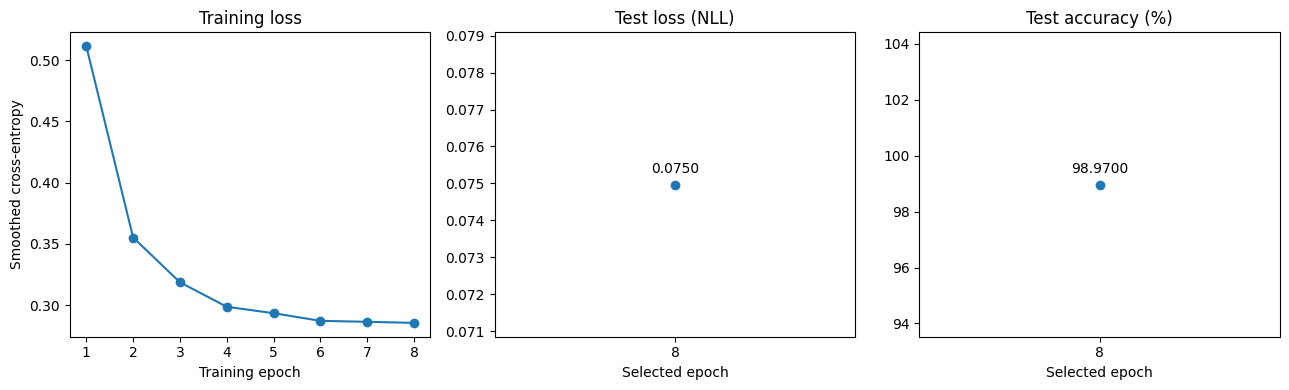

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

report_path = Path("outputs/arti502_completed/challenge_21k_v1/winner.json")
if report_path.is_file():
    winner = json.loads(report_path.read_text())
else:
    from google.colab import files
    print("Select winner.json from the completed 21k experiment.")
    uploaded_report = files.upload()
    selected_files = [name for name in uploaded_report if name.lower().endswith(".json")]
    if len(selected_files) != 1:
        raise ValueError("Select one winner.json report.")
    winner = json.loads(uploaded_report[selected_files[0]])

print("Selected model:", winner["winner"])
print("Weights:", winner["weights"])
print(f"Validation accuracy: {winner['selected']['val_accuracy']:.2f}%")
print(f"Final test accuracy: {winner['test_accuracy']:.2f}% ({winner['correct']}/{winner['total']})")
print(f"Final test loss (NLL): {winner['test_loss']:.6f}")
if winner["winner"] == "ImageNet-21k challenger":
    best_epoch = winner["challenger_best_epoch"]
    history = winner["history"]
    best = next(row for row in history if row["epoch"] == best_epoch)
    print(f"Selected epoch: {best_epoch}")
    print(f"Final train loss (smoothed cross-entropy): {best['train_loss']:.6f}")
    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o")
    axes[0].set(title="Training loss", xlabel="Training epoch", ylabel="Smoothed cross-entropy")
    for axis, metric, label in ((axes[1], "test_loss", "Test loss (NLL)"),
                                (axes[2], "test_accuracy", "Test accuracy (%)")):
        axis.scatter([best_epoch], [winner[metric]])
        axis.set(title=label, xlabel="Selected epoch", xticks=[best_epoch])
        axis.annotate(f"{winner[metric]:.4f}", (best_epoch, winner[metric]),
                      xytext=(0, 8), textcoords="offset points", ha="center")
    fig.tight_layout()
    plt.show()